# 🏡 Real Estate Housing Price Prediction using Ridge and Lasso Regression

**A complete machine-learning workflow on the California Housing dataset**
OLS · Ridge (L2) · Lasso (L1) · GridSearchCV · multicollinearity (VIF) · feature engineering · residual analysis

> Run all cells from top to bottom (`Kernel ▸ Restart & Run All`). Every number in this notebook is computed from real model predictions – nothing is hard-coded.

## 1. Project introduction
Housing prices depend on income, location, age and size of the homes in a neighbourhood. In this notebook we build and compare three **linear regression** models that predict the *median house value* of a California census block group:

| Model | Loss function | Key property |
|---|---|---|
| **OLS** | sum of squared errors | unbiased, no regularisation |
| **Ridge (L2)** | squared errors + α·Σβ² | shrinks correlated coefficients |
| **Lasso (L1)** | squared errors + α·Σ\|β\| | shrinks *and* selects features (zeros) |

## 2. Problem statement
Given the characteristics of a census block group (median income, house age, average rooms/bedrooms, population, occupancy, location and distance to the ocean), predict the **median house value** (`MedHouseVal`, in units of \$100 000).

This is a *continuous regression* problem. The data contain missing values, outliers, correlated predictors and a capped target, so careful preprocessing and model diagnostics are as important as the models themselves.

## 3. Objectives
1. Load and inspect the California Housing data; detect duplicates and missing values.
2. Impute missing numeric values (median) and categorical values (most frequent) **without data leakage**.
3. Detect and handle **multicollinearity** (correlation matrix, VIF, regularisation).
4. Create **interaction / polynomial features** and compare performance before and after.
5. Train **OLS, Ridge and Lasso**; tune α with **GridSearchCV**.
6. Evaluate with **RMSE, MAE and R²** on a reproducible 80:20 hold-out set.
7. Analyse **residuals** for systematic errors and select the best model.

## 4. Dataset description
The file `data/housing.csv` is the public California Housing dataset (1990 census, 20 640 block groups). It stores *totals* per block group; we convert them to the standard per-household features:

| Feature | Meaning | Derived as |
|---|---|---|
| `MedInc` | median income (tens of thousands of USD) | `median_income` |
| `HouseAge` | median house age (years) | `housing_median_age` |
| `AveRooms` | average rooms per household | `total_rooms / households` |
| `AveBedrms` | average bedrooms per household | `total_bedrooms / households` |
| `Population` | block-group population | `population` |
| `AveOccup` | average household occupancy | `population / households` |
| `Latitude`, `Longitude` | location | as given |
| `OceanProximity` | categorical distance to the ocean | `ocean_proximity` |
| **`MedHouseVal`** | **target**, in \$100 000 | `median_house_value / 100 000` |

The CSV also contains 207 missing `total_bedrooms` values – a realistic reason to practise imputation.

## 5. Importing libraries

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning

# make the project's `src` package importable (notebook lives in notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import config as C
from src import data_loader as dl
from src import preprocessing as pp
from src import feature_engineering as fe
from src import evaluation as ev
from src import visualization as viz

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)
RANDOM_STATE = C.RANDOM_STATE      # 42 – every random operation uses this seed
print("Libraries imported. random_state =", RANDOM_STATE)

Libraries imported. random_state = 42


## 6. Dataset loading
`load_california_housing()` reads `data/housing.csv` and converts it to the standard features. It **never** falls back silently to an unrelated dataset – if the data cannot be found, it raises a clear error.

In [2]:
df = dl.load_california_housing()
TARGET = C.CALIFORNIA_TARGET
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,OceanProximity,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,NEAR BAY,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,NEAR BAY,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,NEAR BAY,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,NEAR BAY,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,NEAR BAY,3.422


In [3]:
info = dl.inspect_dataset(df)
print(f"{info['n_rows']:,} rows | {info['n_cols']} columns | {info['total_missing']:,} missing cells | {info['n_duplicates']} duplicate rows")
info["columns"]

20,640 rows | 10 columns | 207 missing cells | 0 duplicate rows


,column,dtype,kind,non_null,missing,missing_pct,unique
0,MedInc,float64,numeric,20640,0,0.000,12928
1,HouseAge,float64,numeric,20640,0,0.000,52
2,AveRooms,float64,numeric,20640,0,0.000,19392
3,AveBedrms,float64,numeric,20433,207,1.003,14121
4,Population,float64,numeric,20640,0,0.000,3888
5,AveOccup,float64,numeric,20640,0,0.000,18841
6,Latitude,float64,numeric,20640,0,0.000,862
7,Longitude,float64,numeric,20640,0,0.000,844
8,OceanProximity,object,categorical,20640,0,0.000,5
9,MedHouseVal,float64,numeric,20640,0,0.000,3842


## 7. Exploratory Data Analysis
We first look at summary statistics, the target distribution, feature distributions and the geography.

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20433.0,1.097,0.476,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


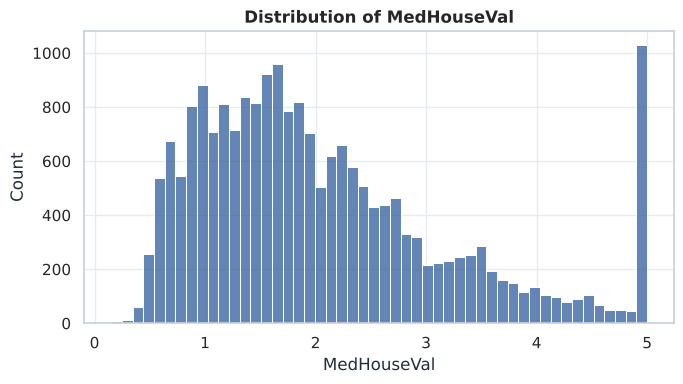

In [5]:
viz.plot_target_distribution(df[TARGET], TARGET)
plt.show()

**Observation.** The target has a sharp spike at its maximum (5.0 = \$500 000): values above that were *capped* when the data were published. Linear models cannot reproduce this censoring – we will see its footprint in the residuals later. Several features (`AveRooms`, `AveOccup`, `Population`) are strongly right-skewed with extreme outliers.

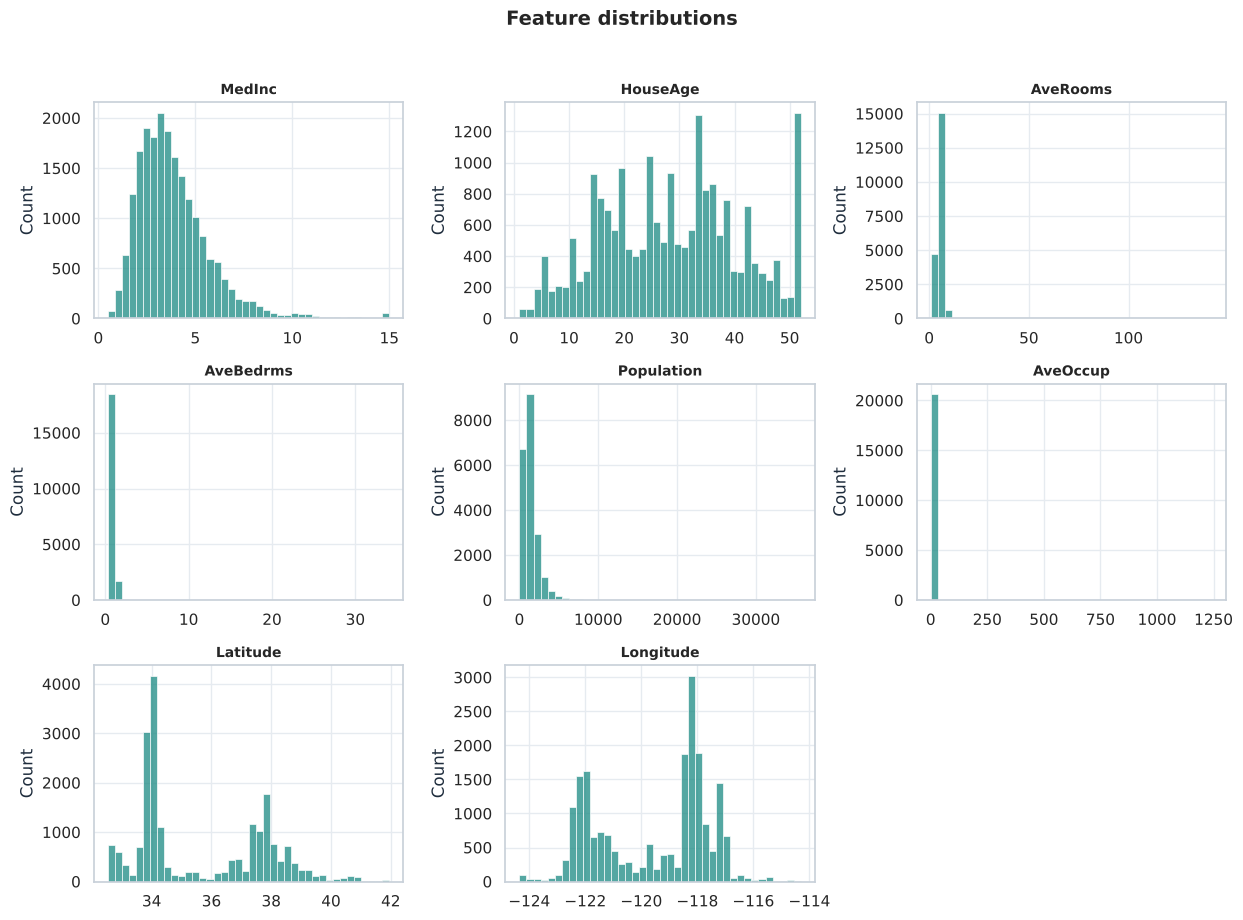

In [6]:
viz.plot_feature_distributions(df, C.CALIFORNIA_NUMERIC)
plt.show()

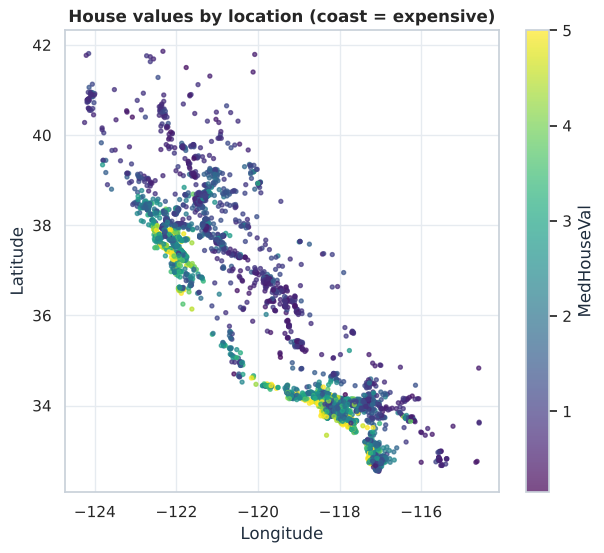

In [7]:
sample = df.sample(6000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(sample.Longitude, sample.Latitude, c=sample[TARGET], cmap="viridis", s=8, alpha=0.7)
plt.colorbar(sc, label=TARGET)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("House values by location (coast = expensive)")
plt.show()

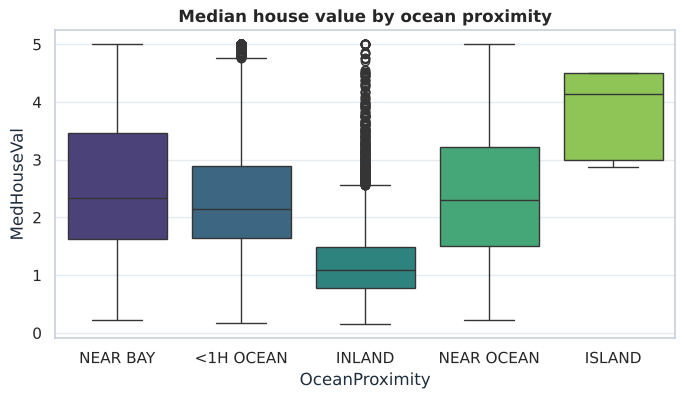

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="OceanProximity", y=TARGET, hue="OceanProximity", palette="viridis", legend=False, ax=ax)
ax.set_title("Median house value by ocean proximity")
plt.show()

## 8. Data cleaning
`prepare_dataset` validates the data, removes **exact duplicate rows** and rows without a target, and returns `X` (features) and `y` (target). Duplicates are removed *before* splitting so that identical rows can never appear in both train and test sets. No statistics are learned in this step.

In [9]:
dup = pp.duplicate_report(df)
print("Duplicate rows:", dup["n_duplicates"])
prep = dl.prepare_dataset(df, TARGET)
X, y = prep["X"], prep["y"]
numeric_cols, categorical_cols = prep["numeric"], prep["categorical"]
print("Rows used       :", len(X))
print("Numeric features:", numeric_cols)
print("Categorical     :", categorical_cols)
print("Removed duplicates / missing-target rows:", prep["n_duplicates_removed"], "/", prep["n_missing_target_removed"])

Duplicate rows: 0
Rows used       : 20640
Numeric features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Categorical     : ['OceanProximity']
Removed duplicates / missing-target rows: 0 / 0


## 9. Missing-value imputation
Missing values are identified first; imputation happens **inside the scikit-learn Pipeline** with statistics learned on the training data only:

* numeric → `SimpleImputer(strategy="median")` (robust to outliers)
* categorical → `SimpleImputer(strategy="most_frequent")`

,column,missing,missing_pct,dtype
0,AveBedrms,207,1.003,float64


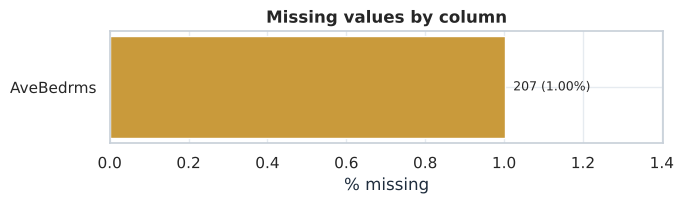

In [10]:
miss = pp.missing_value_report(df)
display(miss[miss.missing > 0])
viz.plot_missing_values(miss)
plt.show()

Only `AveBedrms` has gaps (1.0 %). They are *not* filled now – otherwise the median would be computed using test rows (data leakage). The imputer is created in section 14 and fitted on the training split only.

## 10. Correlation heatmap

Correlation with the target:


MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64

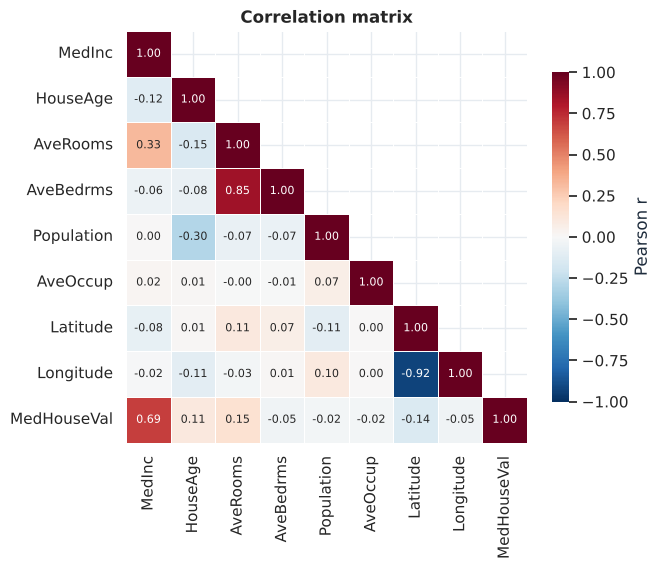

In [11]:
corr = pp.correlation_matrix(df)
viz.plot_correlation_heatmap(corr)
plt.show()
print("Correlation with the target:")
corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3)

`MedInc` is by far the strongest predictor of value. `AveRooms` and `AveBedrms` are correlated with each other, and `Latitude` and `Longitude` are almost perfectly (negatively) correlated because California's coastline runs diagonally – this hints at multicollinearity.

## 11. Multicollinearity analysis
The **Variance Inflation Factor** of feature *j* is `VIF_j = 1 / (1 − R²_j)`, where R²_j comes from regressing feature *j* on all the others. Rules of thumb: VIF < 5 low · 5–10 moderate · > 10 severe.

We compute VIF on the **training split only** (after splitting in section 13 the same split is reused). Here we split first so that every later analysis uses the same data.

,feature,VIF,severity
0,Latitude,9.206,moderate
1,Longitude,8.876,moderate
2,AveRooms,7.917,moderate
3,AveBedrms,6.609,moderate
4,MedInc,2.540,low
5,HouseAge,1.237,low
6,Population,1.135,low
7,AveOccup,1.010,low


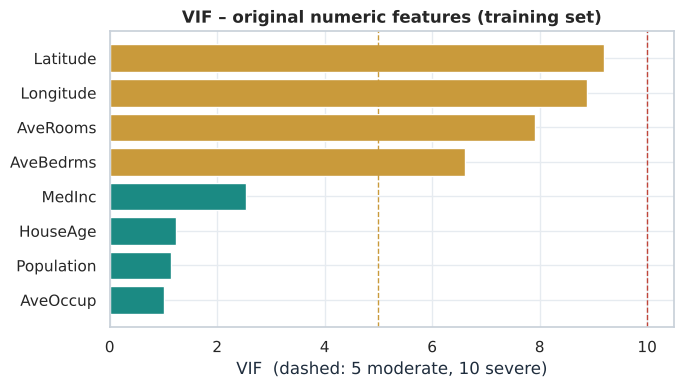

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = pp.split_data(X, y, test_size=C.TEST_SIZE, random_state=RANDOM_STATE)

vif = pp.compute_vif(X_train[numeric_cols])
display(vif)
viz.plot_vif(vif, "VIF – original numeric features (training set)")
plt.show()

In [13]:
print("Highly correlated feature pairs (|r| >= 0.6):")
display(pp.high_correlation_pairs(pp.correlation_matrix(X_train[numeric_cols]), 0.6))

kept, log = pp.vif_prune(X_train[numeric_cols], threshold=C.VIF_THRESHOLD)
print(f"\nPruning at VIF >= {C.VIF_THRESHOLD:g}: dropped {log.dropped_feature.tolist() or 'nothing'}")
kept5, log5 = pp.vif_prune(X_train[numeric_cols], threshold=C.VIF_MODERATE)
print(f"Pruning at VIF >= {C.VIF_MODERATE:g}: dropped {log5.dropped_feature.tolist()}")
log5

Highly correlated feature pairs (|r| >= 0.6):

Pruning at VIF >= 10: dropped nothing
Pruning at VIF >= 5: dropped ['Latitude', 'AveRooms']


,feature_1,feature_2,correlation
0,Latitude,Longitude,-0.9245
1,AveRooms,AveBedrms,0.8362


,step,dropped_feature,VIF_at_drop
0,1,Latitude,9.206
1,2,AveRooms,7.192


**Handling multicollinearity.** No feature reaches the severe threshold of 10, but four (`Latitude`, `Longitude`, `AveRooms`, `AveBedrms`) are moderate (> 5). We use three safeguards:

1. **Regularisation** – Ridge and Lasso are designed for correlated predictors.
2. **Mean-centring** before building product terms (section 12), which removes the artificial collinearity between a product and its parents.
3. **Empirical test** – a *VIF-pruned* feature set (VIF < 5) is trained and compared; if removing features hurts accuracy we keep them (see section 19).

## 12. Feature engineering
Interaction features let a *linear* model represent effects that depend on a combination of variables:

* `MedInc × HouseAge`, `AveRooms × HouseAge`, `Population × AveOccup` (as requested)
* `Latitude × Longitude` – a simple geographic interaction
* `AveBedrms / AveRooms` – share of rooms that are bedrooms

Implementation notes (all inside the `InteractionFeatures` transformer): operands are clipped to their 1st–99th training percentile (a single block group with 1 243 occupants would otherwise dominate every product) and mean-centred before multiplication. We also try a **degree-2 polynomial** expansion (with the same clipping).

In [14]:
spec = fe.suggest_engineering_spec(X_train, y_train, numeric_cols)
display(fe.describe_spec(spec))

# look at the engineered columns on a few training rows
demo_pre = pp.build_preprocessor(numeric_cols, categorical_cols, "interaction", spec).fit(X_train)
demo = pp.transform_to_frame(demo_pre, X_train)
demo.iloc[:5, :].round(3)

,feature,type,formula
0,MedInc_x_HouseAge,interaction,(clip(MedInc) − mean) × (clip(HouseAge) − mean)
1,AveRooms_x_HouseAge,interaction,(clip(AveRooms) − mean) × (clip(HouseAge) − mean)
2,Population_x_AveOccup,interaction,(clip(Population) − mean) × (clip(AveOccup) − ...
3,Latitude_x_Longitude,interaction,(clip(Latitude) − mean) × (clip(Longitude) − m...
4,AveBedrms_per_AveRooms,ratio,clip(AveBedrms) / clip(AveRooms)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedInc_x_HouseAge,AveRooms_x_HouseAge,Population_x_AveOccup,Latitude_x_Longitude,AveBedrms_per_AveRooms,OceanProximity_INLAND,OceanProximity_ISLAND,OceanProximity_NEAR BAY,OceanProximity_NEAR OCEAN
14196,-0.326,0.348,-0.175,-0.208,0.768,0.051,-1.373,1.273,0.015,0.140,0.712,-1.261,-0.217,0.0,0.0,0.0,1.0
8267,-0.036,1.618,-0.403,-0.129,-0.099,-0.117,-0.877,0.709,0.084,-0.798,-0.048,0.436,0.381,0.0,0.0,0.0,1.0
17445,0.145,-1.953,0.088,-0.258,-0.450,-0.032,-0.460,-0.448,-0.179,-0.208,-0.065,1.681,-0.703,0.0,0.0,0.0,1.0
14265,-1.018,0.587,-0.600,-0.145,-0.007,0.078,-1.382,1.233,-0.471,-0.348,-0.169,-1.196,0.857,0.0,0.0,0.0,1.0
2271,-0.171,1.142,0.349,0.087,-0.486,-0.069,0.532,-0.109,-0.060,0.989,0.235,1.284,-0.583,1.0,0.0,0.0,0.0


In [15]:
n_base = len(pp.transformed_feature_names(pp.build_preprocessor(numeric_cols, categorical_cols, "none").fit(X_train)))
n_poly = len(pp.transformed_feature_names(pp.build_preprocessor(numeric_cols, categorical_cols, "poly").fit(X_train)))
print(f"Model inputs  baseline: {n_base} | interaction: {demo.shape[1]} | polynomial (degree 2): {n_poly}")

Model inputs  baseline: 12 | interaction: 17 | polynomial (degree 2): 48


## 13. Train–test splitting
The split was performed in section 11 with `test_size=0.2` and `random_state=42` → a reproducible **80 : 20** split. All fitting (imputation, scaling, encoding, model parameters, α search) uses `X_train` only.

In [16]:
print(f"Train: {len(X_train):,} rows ({len(X_train)/len(X):.0%})  |  Test: {len(X_test):,} rows ({len(X_test)/len(X):.0%})")
# reproducibility check: the same seed gives the identical split
X_train2, _, _, _ = pp.split_data(X, y)
print("Split reproducible:", X_train.index.equals(X_train2.index))
print("Missing AveBedrms  train / test:", int(X_train.AveBedrms.isna().sum()), "/", int(X_test.AveBedrms.isna().sum()))

Train: 16,512 rows (80%)  |  Test: 4,128 rows (20%)
Split reproducible: True
Missing AveBedrms  train / test: 0 / 207


## 14. Feature scaling and encoding
`ColumnTransformer` applies different steps per column type:

* **numeric**: median imputation → (feature engineering) → `StandardScaler`
* **categorical**: most-frequent imputation → `OneHotEncoder` (first level dropped to avoid the dummy-variable trap)

Scaling matters for Ridge and Lasso because the penalty treats every coefficient equally – unscaled features would be penalised unevenly.

In [17]:
pre = pp.build_preprocessor(numeric_cols, categorical_cols, "none")
pre.fit(X_train)                       # statistics learned from TRAIN only
Z_train, Z_test = pre.transform(X_train), pre.transform(X_test)
names = pp.transformed_feature_names(pre)
print("Transformed shape:", Z_train.shape, "| NaNs left:", int(np.isnan(Z_train).sum() + np.isnan(Z_test).sum()))
desc = pp.describe_fitted_preprocessor(pre)
display(desc["numeric_imputer"])
display(desc["onehot"])
pd.DataFrame(Z_train, columns=names).describe().loc[["mean", "std"]].round(3)

Transformed shape: (16512, 12) | NaNs left: 0


,feature,median_used
0,MedInc,3.5458
1,HouseAge,29.0000
2,AveRooms,5.2359
3,AveBedrms,1.0493
4,Population,1167.0000
5,AveOccup,2.8172
6,Latitude,34.2600
7,Longitude,-118.5100


,feature,category,encoded_as
0,OceanProximity,<1H OCEAN,baseline (dropped)
1,OceanProximity,INLAND,OceanProximity_INLAND
2,OceanProximity,ISLAND,OceanProximity_ISLAND
3,OceanProximity,NEAR BAY,OceanProximity_NEAR BAY
4,OceanProximity,NEAR OCEAN,OceanProximity_NEAR OCEAN


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,OceanProximity_INLAND,OceanProximity_ISLAND,OceanProximity_NEAR BAY,OceanProximity_NEAR OCEAN
mean,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.317,0.000,0.112,0.126
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.465,0.016,0.316,0.332


The scaled numeric training columns have mean ≈ 0 and standard deviation ≈ 1; the one-hot columns are 0/1 indicators.

## 15. OLS model implementation
Every model is a `Pipeline([preprocessor, estimator])`. When we cross-validate or grid-search the pipeline, the preprocessor is **re-fitted inside every fold**, so the validation fold never influences imputation or scaling.

We train each model on four feature sets – *Baseline*, *VIF-pruned*, *Interaction* and *Polynomial* – to measure the effect of feature engineering. OLS first:

In [18]:
cv = KFold(n_splits=C.CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"

FEATURE_SETS = {
    "Baseline (original features)": dict(numeric=numeric_cols, mode="none", spec=None),
    f"VIF-pruned (VIF<{C.VIF_MODERATE:g})": dict(numeric=kept5, mode="none", spec=None),
    "Interaction features": dict(numeric=numeric_cols, mode="interaction", spec=spec),
    "Polynomial (degree 2)": dict(numeric=numeric_cols, mode="poly", spec=None),
}
def make_pre(cfg):
    return pp.build_preprocessor(cfg["numeric"], categorical_cols, cfg["mode"], cfg["spec"])

fitted = {name: {} for name in FEATURE_SETS}     # fitted[feature_set][model]
cv_rmse = {name: {} for name in FEATURE_SETS}    # cross-validated RMSE on the training data
best_alpha = {name: {} for name in FEATURE_SETS}
grids = {name: {} for name in FEATURE_SETS}

for fs, cfg in FEATURE_SETS.items():
    ols = Pipeline([("preprocessor", make_pre(cfg)), ("model", LinearRegression())])
    scores = -cross_val_score(ols, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    ols.fit(X_train, y_train)
    fitted[fs]["OLS"], cv_rmse[fs]["OLS"] = ols, scores.mean()
    print(f"OLS   | {fs:32s} CV RMSE = {scores.mean():.4f} (± {scores.std():.4f})")

OLS   | Baseline (original features)     CV RMSE = 0.7122 (± 0.0142)
OLS   | VIF-pruned (VIF<5)               CV RMSE = 0.7282 (± 0.0144)
OLS   | Interaction features             CV RMSE = 0.6996 (± 0.0148)
OLS   | Polynomial (degree 2)            CV RMSE = 0.5930 (± 0.0153)


*Interpretation:* OLS has no hyper-parameters. Its cross-validated RMSE is our reference for what regularisation can improve on.

## 16. Ridge regression implementation
Ridge minimises `Σ(y − ŷ)² + α·Σβ²`. A larger α shrinks all coefficients towards zero (lower variance, higher bias). The best α is found in section 18.

In [19]:
RIDGE_GRID = {"model__alpha": list(C.RIDGE_ALPHAS)}
print("Ridge alphas:", np.round(C.RIDGE_ALPHAS, 4))

Ridge alphas: [1.000000e-03 3.200000e-03 1.000000e-02 3.160000e-02 1.000000e-01
 3.162000e-01 1.000000e+00 3.162300e+00 1.000000e+01 3.162280e+01
 1.000000e+02 3.162278e+02 1.000000e+03]


## 17. Lasso regression implementation
Lasso minimises `Σ(y − ŷ)² + α·Σ|β|`. The L1 penalty can set coefficients **exactly to zero**, so Lasso doubles as a feature selector.

In [20]:
LASSO_GRID = {"model__alpha": list(C.LASSO_ALPHAS)}
print("Lasso alphas:", np.round(C.LASSO_ALPHAS, 5))

Lasso alphas: [1.0000e-04 3.2000e-04 1.0000e-03 3.1600e-03 1.0000e-02 3.1620e-02
 1.0000e-01 3.1623e-01 1.0000e+00]


## 18. GridSearchCV optimisation
`GridSearchCV` evaluates every α with 5-fold cross-validation on the training data, scoring by (negative) RMSE, and refits the best pipeline on the full training set. *(This cell trains 4 feature sets × 2 models × several α values × 5 folds, so it takes about a minute.)*

In [21]:
for fs, cfg in FEATURE_SETS.items():
    for name, est, grid in (("Ridge", Ridge(random_state=RANDOM_STATE), RIDGE_GRID),
                            ("Lasso", Lasso(max_iter=5000, tol=1e-3, random_state=RANDOM_STATE), LASSO_GRID)):
        gs = GridSearchCV(Pipeline([("preprocessor", make_pre(cfg)), ("model", est)]),
                          param_grid=grid, scoring=SCORING, cv=cv, n_jobs=-1, refit=True, return_train_score=True)
        gs.fit(X_train, y_train)
        fitted[fs][name] = gs.best_estimator_
        cv_rmse[fs][name] = -gs.best_score_
        best_alpha[fs][name] = gs.best_params_["model__alpha"]
        res = pd.DataFrame(gs.cv_results_)
        grids[fs][name] = pd.DataFrame({
            "alpha": res.param_model__alpha.astype(float), "cv_rmse": -res.mean_test_score,
            "cv_rmse_std": res.std_test_score, "train_rmse": -res.mean_train_score}).sort_values("alpha").reset_index(drop=True)

best_table = pd.DataFrame(cv_rmse).T[C.MODEL_NAMES]
best_table["Ridge best α"] = [best_alpha[fs]["Ridge"] for fs in FEATURE_SETS]
best_table["Lasso best α"] = [best_alpha[fs]["Lasso"] for fs in FEATURE_SETS]
best_table.round(5)

,OLS,Ridge,Lasso,Ridge best α,Lasso best α
Baseline (original features),0.71224,0.71214,0.71219,1.000,0.0001
VIF-pruned (VIF<5),0.72819,0.72810,0.72814,1.000,0.0001
Interaction features,0.69965,0.69956,0.69961,1.000,0.0001
Polynomial (degree 2),0.59304,0.59303,0.60446,0.001,0.0001


The table lists the cross-validated RMSE of every model for each feature set, together with the optimal α values found by the grid search (lower RMSE is better).

## 19. Model evaluation
**Feature-set selection uses cross-validation on the training data only**, so the test set stays untouched until the final report. The selected feature set is the one with the lowest cross-validated RMSE of its best model. Afterwards we show test-set results for *all* sets to quantify the effect of feature engineering.

In [22]:
rows = []
for fs in FEATURE_SETS:
    row = {"feature_set": fs, "n_inputs": len(fitted[fs]["OLS"].named_steps["preprocessor"].get_feature_names_out())}
    for m in C.MODEL_NAMES:
        row[f"{m} CV RMSE"] = cv_rmse[fs][m]
        row[f"{m} test RMSE"] = ev.regression_metrics(y_test, fitted[fs][m].predict(X_test))["RMSE"]
    row["best CV RMSE"] = min(cv_rmse[fs].values())
    rows.append(row)
fs_table = pd.DataFrame(rows)
display(fs_table.round(4))

selected_fs = fs_table.loc[fs_table["best CV RMSE"].idxmin(), "feature_set"]
print("Selected feature set (lowest CV RMSE):", selected_fs)
base_rmse = fs_table.loc[0, [f"{m} test RMSE" for m in C.MODEL_NAMES]].min()
sel_rmse = fs_table.loc[fs_table.feature_set == selected_fs, [f"{m} test RMSE" for m in C.MODEL_NAMES]].min(axis=1).iloc[0]
print(f"Best test RMSE: baseline {base_rmse:.4f}  ->  selected {sel_rmse:.4f}  ({100*(base_rmse-sel_rmse)/base_rmse:+.1f}% improvement)")

Selected feature set (lowest CV RMSE): Polynomial (degree 2)
Best test RMSE: baseline 0.7330  ->  selected 0.6014  (+18.0% improvement)


,feature_set,n_inputs,OLS CV RMSE,OLS test RMSE,Ridge CV RMSE,Ridge test RMSE,Lasso CV RMSE,Lasso test RMSE,best CV RMSE
0,Baseline (original features),12,0.7122,0.7330,0.7121,0.7331,0.7122,0.7331,0.7121
1,VIF-pruned (VIF<5),10,0.7282,0.7383,0.7281,0.7384,0.7281,0.7385,0.7281
2,Interaction features,17,0.6996,0.7076,0.6996,0.7078,0.6996,0.7079,0.6996
3,Polynomial (degree 2),48,0.5930,0.6014,0.5930,0.6014,0.6045,0.6133,0.5930


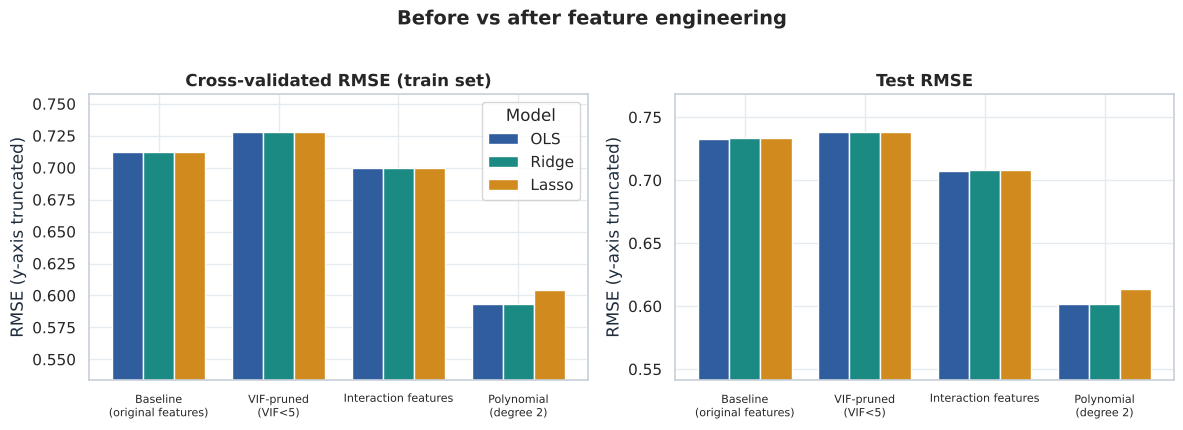

In [23]:
# adapt the table to the plotting helper (expects *_cv_rmse / *_test_rmse columns)
plot_df = pd.DataFrame({"feature_set": fs_table.feature_set})
for m in C.MODEL_NAMES:
    plot_df[f"{m}_cv_rmse"] = fs_table[f"{m} CV RMSE"]
    plot_df[f"{m}_test_rmse"] = fs_table[f"{m} test RMSE"]
viz.plot_feature_set_comparison(plot_df)
plt.show()

**Reading the chart.** Interaction features give a modest gain over the baseline; the degree-2 polynomial expansion captures much more of the non-linear structure (especially the geography) and clearly lowers the error. Pruning features by VIF *hurts* – the "collinear" variables (latitude, longitude, rooms) carry real signal, so regularisation is the better remedy than removal. This confirms the guideline: keep features that improve cross-validated generalisation and reject the ones that do not.

In [24]:
models = fitted[selected_fs]
best_params = {"OLS": {}, "Ridge": {"alpha": best_alpha[selected_fs]["Ridge"]}, "Lasso": {"alpha": best_alpha[selected_fs]["Lasso"]}}
metrics = ev.evaluate_models(models, X_train, y_train, X_test, y_test, cv_rmse[selected_fs], best_params)
print("Selected feature set:", selected_fs)
metrics.round(4)

Selected feature set: Polynomial (degree 2)


,Model,Best Params,CV RMSE,Train RMSE,Train MAE,Train R²,Test RMSE,Test MAE,Test R²,R² Gap (Train−Test),Non-zero Coefs,Total Coefs
0,OLS,—,0.5930,0.5904,0.4166,0.7393,0.6014,0.4216,0.7240,0.0153,48,48
1,Ridge,alpha=0.001,0.5930,0.5904,0.4167,0.7393,0.6014,0.4217,0.7240,0.0153,48,48
2,Lasso,alpha=0.0001,0.6045,0.6023,0.4304,0.7286,0.6133,0.4357,0.7129,0.0157,45,48


## 20. RMSE, MAE and R² comparison

Model,Best Params,Test RMSE,Test MAE,Test R²
OLS,—,0.601400,0.421600,0.724000
Ridge,alpha=0.001,0.601400,0.421700,0.724000
Lasso,alpha=0.0001,0.613300,0.435700,0.712900


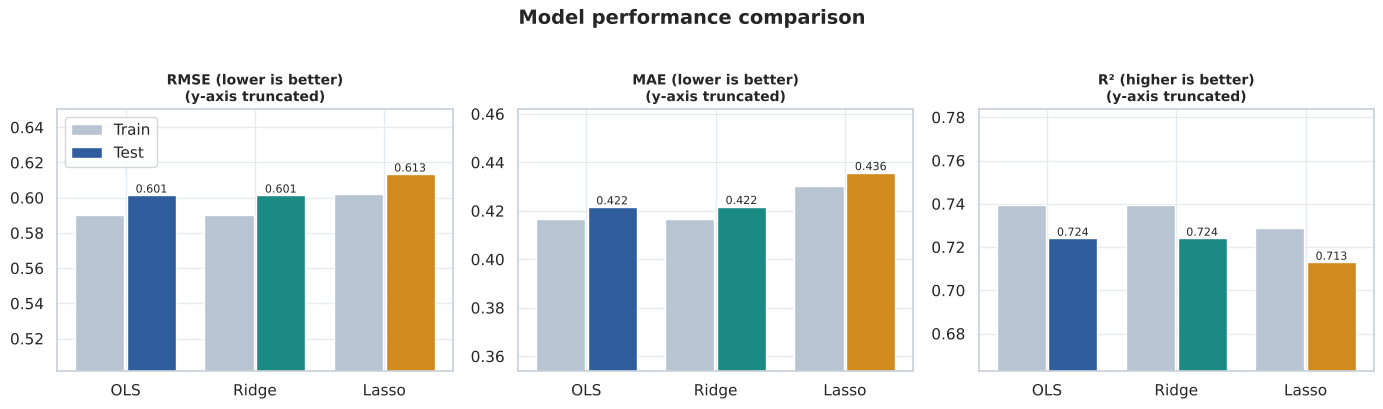

In [25]:
display(metrics[["Model", "Best Params", "Test RMSE", "Test MAE", "Test R²"]].round(4).style.hide(axis="index")
        .highlight_min(subset=["Test RMSE", "Test MAE"], color="#cdeee9").highlight_max(subset=["Test R²"], color="#cdeee9"))
viz.plot_model_performance(metrics)
plt.show()

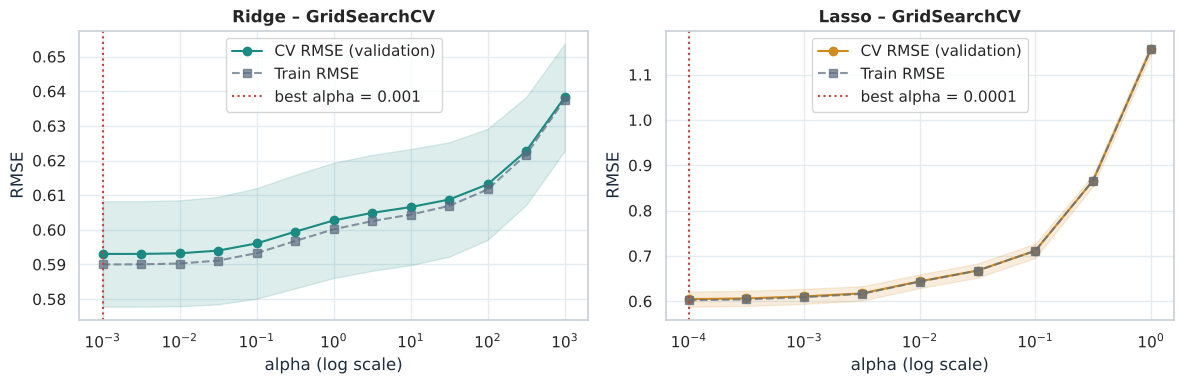

In [26]:
viz.plot_gridsearch({m: grids[selected_fs][m] for m in ["Ridge", "Lasso"]}, best_params)
plt.show()

The three models are almost indistinguishable: with ~16 500 training rows and a small number of features the un-penalised OLS fit has very little variance for regularisation to remove. Lasso's best α is at the small end of the grid, i.e. the data prefer *little* penalty.

Coefficients exactly zero: {'OLS': 0, 'Ridge': 0, 'Lasso': 3} of 48


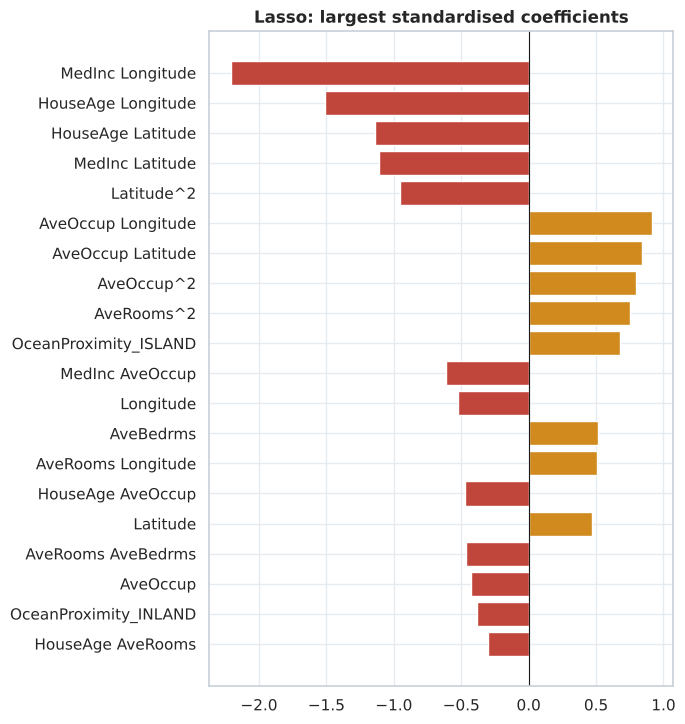

In [27]:
coefs = {m: ev.coefficient_table(models[m]) for m in C.MODEL_NAMES}
print("Coefficients exactly zero:", {m: int((c.coefficient.abs() <= 1e-10).sum()) for m, c in coefs.items()}, "of", len(coefs["OLS"]))
viz.plot_coefficients(coefs["Lasso"], "Lasso")
plt.show()

## 21. Actual vs predicted visualisation

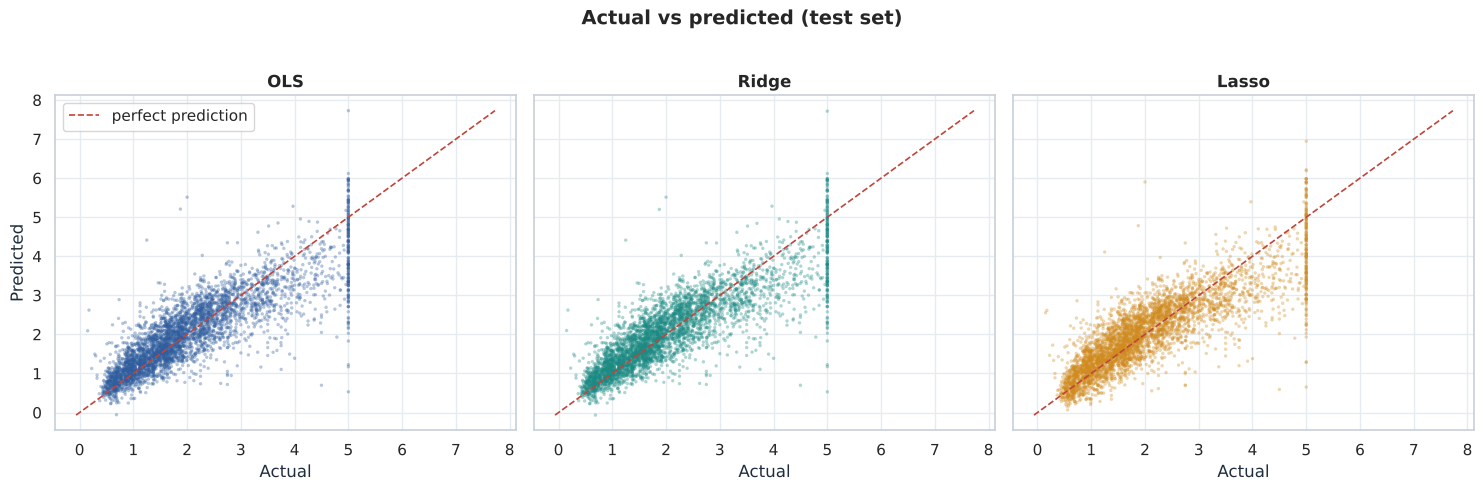

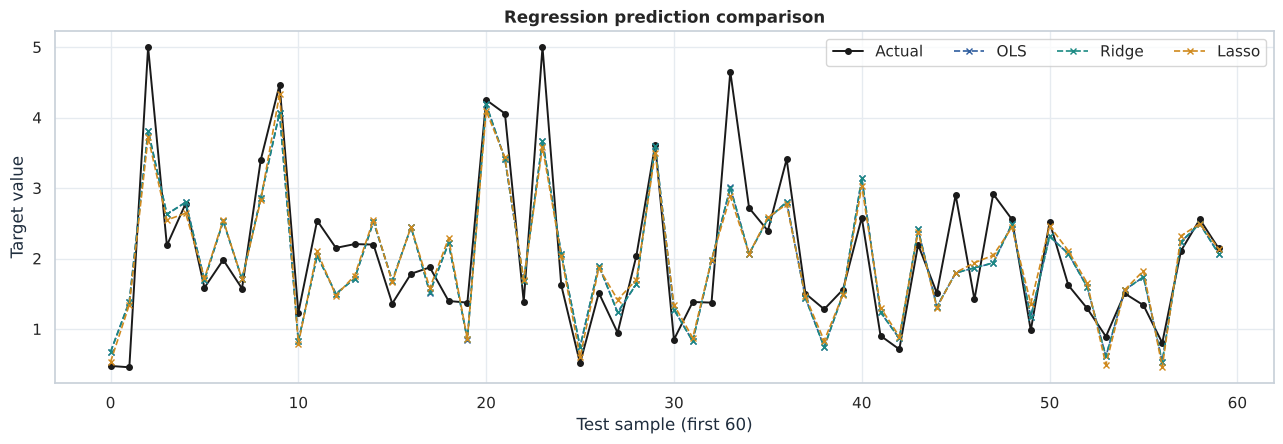

In [28]:
preds = pd.DataFrame({"actual": y_test.values})
for m in C.MODEL_NAMES:
    preds[m] = models[m].predict(X_test)
viz.plot_actual_vs_predicted(preds)
plt.show()
viz.plot_prediction_comparison(preds, n=60)
plt.show()

Points scatter around the dashed ideal line. The horizontal band of actual values at 5.0 (the capped target) is predicted anywhere between 2 and 6, which creates the characteristic “wall” on the right of the plot.

## 22. Residual error analysis

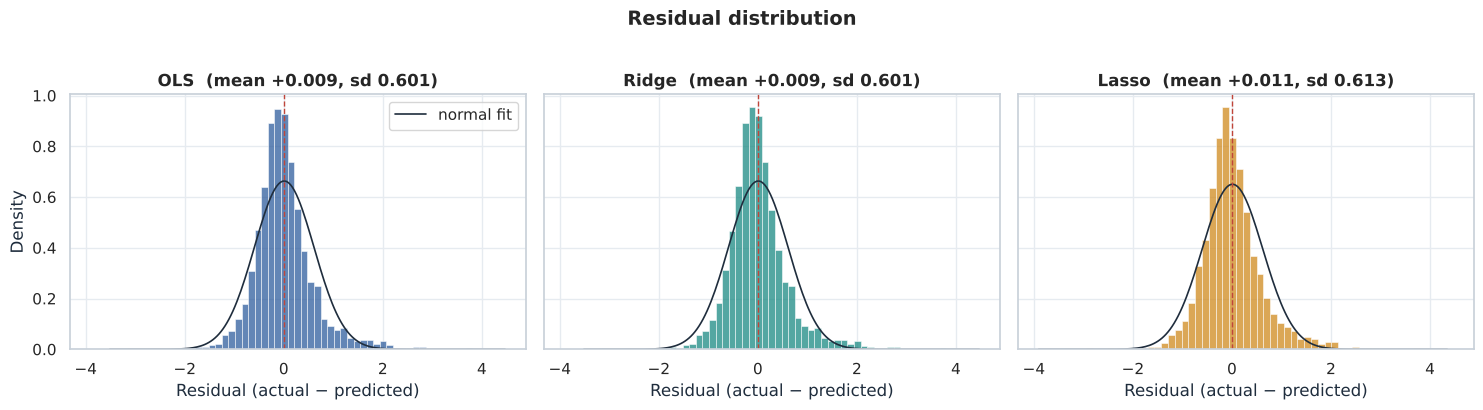

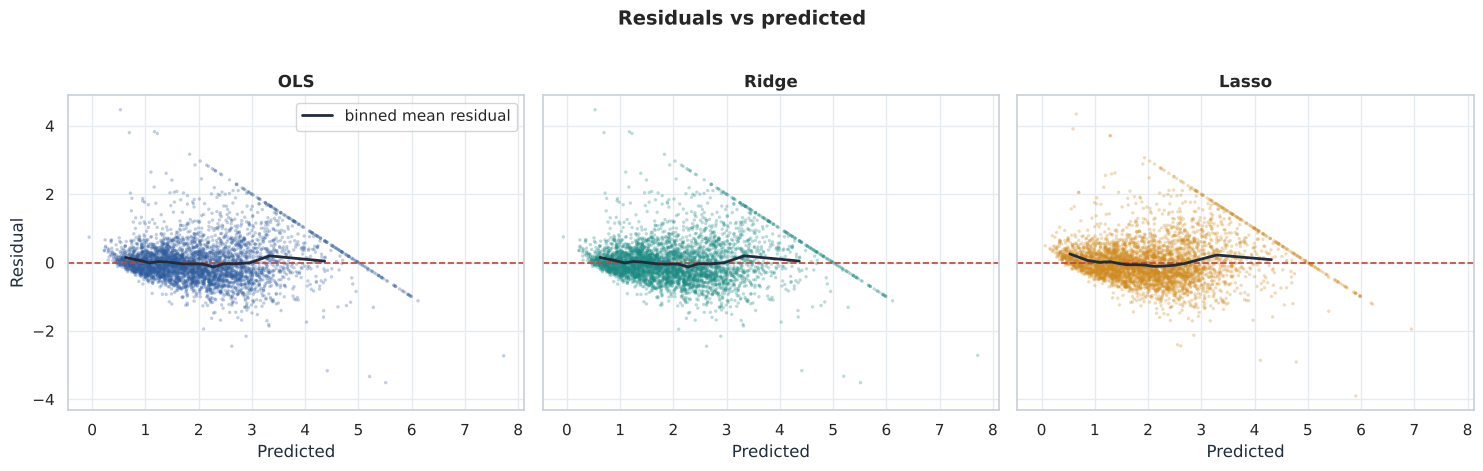

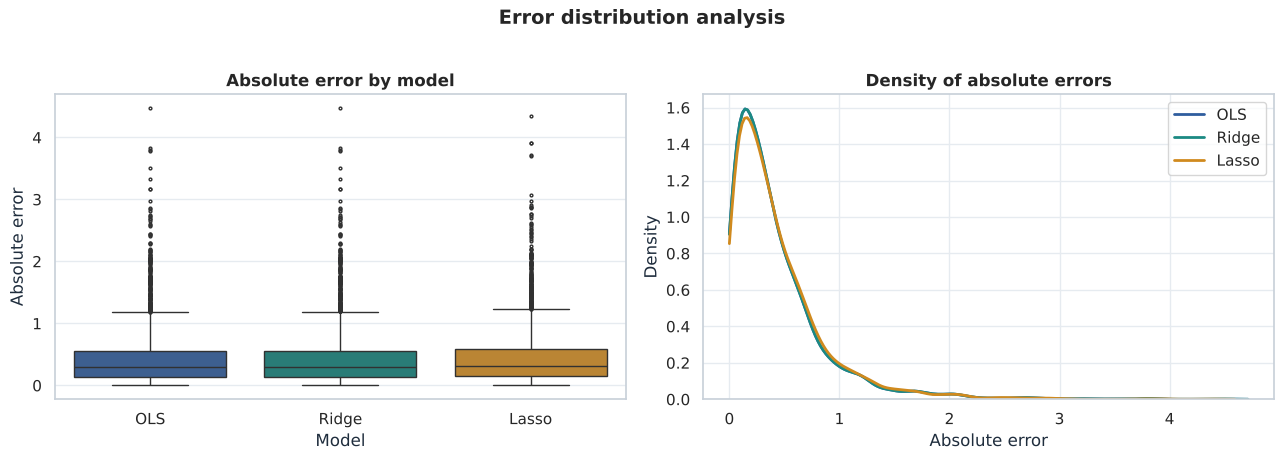

In [29]:
viz.plot_residual_hist(preds); plt.show()
viz.plot_residual_vs_predicted(preds); plt.show()
viz.plot_error_distribution(preds); plt.show()

{'mean': 0.0089, 'std': 0.6014, 'skew': 1.0362, 'excess_kurtosis': 4.9109, 'normality_p': 0.0, 'corr_resid_pred': -0.0272, 'hetero_spearman': 0.3502, 'hetero_p': 0.0, 'decile_bias_index': 0.1973, 'share_beyond_2sd': 0.0521, 'max_over_prediction': -3.5132, 'max_under_prediction': 4.4698}
• Verdict: the residuals are not purely random noise. Systematic effects remain because error variance grows with the predicted value (heteroscedasticity); the capped target cannot be reproduced by a linear model; the residuals are skewed / heavy-tailed.
• Overall bias is negligible (mean residual +0.0089).
• Residuals are centred around zero in every prediction decile (largest decile bias = 0.20σ), so there is no strong systematic over/under-prediction pattern.
• Error size changes with the predicted value (Spearman ρ between |residual| and prediction = +0.35) – evidence of heteroscedasticity.
• The residual distribution is non-normal (skew +1.04, excess kurtosis 4.91): a few large errors dominate RMSE

,decile,mean_pred,mean_residual,std_residual,n
0,1,0.6981,0.1129,0.4132,413
1,2,1.0359,0.0201,0.4044,413
2,3,1.2979,0.0336,0.4669,413
3,4,1.5301,-0.0152,0.4542,412
4,5,1.7798,-0.0547,0.5239,413
5,6,2.0380,-0.0310,0.5907,413
6,7,2.3289,-0.0988,0.6937,412
7,8,2.6475,-0.0342,0.6761,413
8,9,3.0454,0.0371,0.8104,413
9,10,4.0590,0.1187,0.7768,413


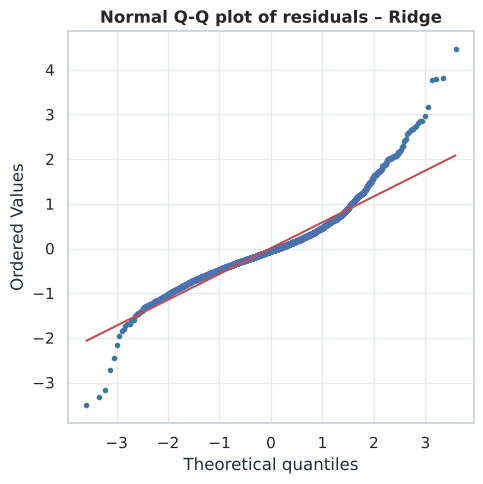

In [30]:
best_guess = metrics.sort_values("Test RMSE").Model.iloc[0]
viz.plot_qq(preds, best_guess); plt.show()
cap_value, cap_share = float(y.max()), float((y == y.max()).mean())
target_cap = {"value": cap_value, "share": cap_share} if cap_share >= 0.005 else None
stats_best = ev.residual_analysis(preds.actual, preds[best_guess])
print({k: round(v, 4) for k, v in stats_best.items() if k != "decile_table"})
display(stats_best["decile_table"].round(4))
for line in ev.interpret_residuals(stats_best, preds.actual, preds[best_guess], target_cap):
    print("•", line.replace("**", ""))

**Do the residuals indicate systematic error?** The numbers above are generated from the actual residuals:

* the **mean residual is ≈ 0** and the decile table shows no large over-/under-prediction at any price level, so there is no gross bias;
* but the **error spread grows with the predicted price** (heteroscedasticity), the distribution is **right-skewed with heavy tails**, and the **capped target** produces large positive residuals for the most expensive areas.

So the residuals are *not* pure noise: a linear model leaves systematic, price-dependent structure behind. Transforming the target (e.g. log), modelling the censoring, or using non-linear models would be the next steps.

## 23. Best model selection

In [31]:
best_name, explanation = ev.select_best_model(metrics)
print("BEST MODEL:", best_name)
print(explanation.replace("**", ""))

BEST MODEL: Ridge
Ridge is the best model: it has the lowest test-set RMSE (0.6014), together with MAE 0.4217 and R² 0.7240. The runner-up, OLS, has RMSE 0.6014 – the two are tied to within 0.05%. The gap is below 1%, so the models are practically equivalent in accuracy; Ridge wins on the stated criterion (lowest test RMSE). Its train–test R² gap is +0.0153 and its cross-validated RMSE is 0.5930, which indicates good generalisation (no sign of over-fitting). Ridge shrinks correlated coefficients towards zero, which stabilises estimates when features are collinear.


## 24. Final conclusion

In [32]:
m = metrics.set_index("Model")
ranked = metrics.sort_values("Test RMSE")
print(f"""FINAL CONCLUSION
================
Feature set chosen by cross-validation : {selected_fs}
Best model (lowest test RMSE)          : {best_name}
    RMSE = {m.loc[best_name, 'Test RMSE']:.4f}   MAE = {m.loc[best_name, 'Test MAE']:.4f}   R² = {m.loc[best_name, 'Test R²']:.4f}
Test RMSE  OLS / Ridge / Lasso         : {m.loc['OLS','Test RMSE']:.4f} / {m.loc['Ridge','Test RMSE']:.4f} / {m.loc['Lasso','Test RMSE']:.4f}
Best alphas                            : Ridge = {best_params['Ridge']['alpha']:.4g}, Lasso = {best_params['Lasso']['alpha']:.4g}
Feature engineering effect on best test RMSE : {base_rmse:.4f} -> {sel_rmse:.4f} ({100*(base_rmse-sel_rmse)/base_rmse:+.1f}%)
Generalisation (train R² - test R²)    : {m.loc[best_name, 'R² Gap (Train−Test)']:+.4f}
""")

FINAL CONCLUSION
Feature set chosen by cross-validation : Polynomial (degree 2)
Best model (lowest test RMSE)          : Ridge
    RMSE = 0.6014   MAE = 0.4217   R² = 0.7240
Test RMSE  OLS / Ridge / Lasso         : 0.6014 / 0.6014 / 0.6133
Best alphas                            : Ridge = 0.001, Lasso = 0.0001
Feature engineering effect on best test RMSE : 0.7330 -> 0.6014 (+18.0%)
Generalisation (train R² - test R²)    : +0.0153



### Key takeaways
1. **Feature engineering mattered more than the choice of model.** Going from the original features to a polynomial expansion reduced test RMSE substantially, while OLS, Ridge and Lasso differ only in the third decimal.
2. **Multicollinearity was moderate, not severe** (all VIF < 10). Removing the collinear variables made the models worse, so regularisation – not deletion – is the appropriate safeguard.
3. **Regularisation helps when data are scarce or features very correlated.** Here there is ample data, so the optimal penalty is tiny and Ridge ≈ OLS; Lasso's stronger shrinkage costs a little accuracy.
4. **Residuals show systematic structure** (heteroscedasticity, skew, capped target). The models are reliable for typical neighbourhoods but under-predict very expensive ones.

### Limitations and next steps
Try a log-transformed target, tree-based models (gradient boosting) or spatial features such as distance to major cities, and add confidence intervals. The Streamlit dashboard (`streamlit run app.py`) reuses exactly the same code for interactive exploration and prediction.